# Extra Practical: Dimensionality Reduction, Neural Networks and Ensemble Learning
**Project:** Groundwater Level Prediction & Risk Classification
**Covers syllabus Units V and VI:** PCA, Feedforward Neural Network / Multi-layer Perceptron, Bias-variance trade-off, Bagging, Boosting and Random Forest.

**Input files:** `03_wells_with_risk.csv`, `06_classification_results.csv`, `07_district_clusters.csv`
**Output files:** `08_final_model_comparison.csv` and `09_priority_districts.csv`

**Aim:** try the remaining techniques, understand the bias-variance trade-off, compare **all** models in one final table, and finish with a list of the districts that need attention first.

## Step 1: Load the data and the saved train/test split
**What to say:** *Same file and same split as the earlier practicals, so every model is tested on the same hidden wells.*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("03_wells_with_risk.csv")

features = ["Latitude", "Longitude", "Well_Depth (meters)", "pre_mean", "post_mean", "recharge", "change", "Pre_2021"]
labels = ["Safe", "Watch", "Critical", "Severe"]          # risk codes 0, 1, 2, 3

train = df[df["set"] == "train"]
test = df[df["set"] == "test"]
X_train, X_test = train[features], test[features]
y_train, y_test = train["risk_code"], test["risk_code"]

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)          # fitted on training wells only
X_test_s = scaler.transform(X_test)

print("Training wells:", len(train), "| Test wells:", len(test))

Training wells: 1478 | Test wells: 370


## Step 2: Evaluation function
**What to say:** *The same measures as in Practicals 4 and 5, so the new models can be added to the same table.*

In [5]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             log_loss, roc_auc_score, ConfusionMatrixDisplay)

results = []
predictions = {}

def evaluate(name, pred, proba):
    results.append({"Model": name,
                    "Accuracy": accuracy_score(y_test, pred),
                    "Precision": precision_score(y_test, pred, average="macro"),
                    "Recall": recall_score(y_test, pred, average="macro"),
                    "F1": f1_score(y_test, pred, average="macro"),
                    "At-risk recall": recall_score(y_test >= 2, pred >= 2),
                    "Log loss": log_loss(y_test, proba),
                    "AUC": roc_auc_score(y_test, proba, multi_class="ovr")})
    predictions[name] = pred

## Step 3: Principal Component Analysis (PCA)
**What to say:** *Our 8 features overlap a lot (for example average depth and last year's depth are almost the same). PCA combines them into a few new, uncorrelated features called principal components, ordered by how much of the variation they keep. It is fitted on the training wells only.*

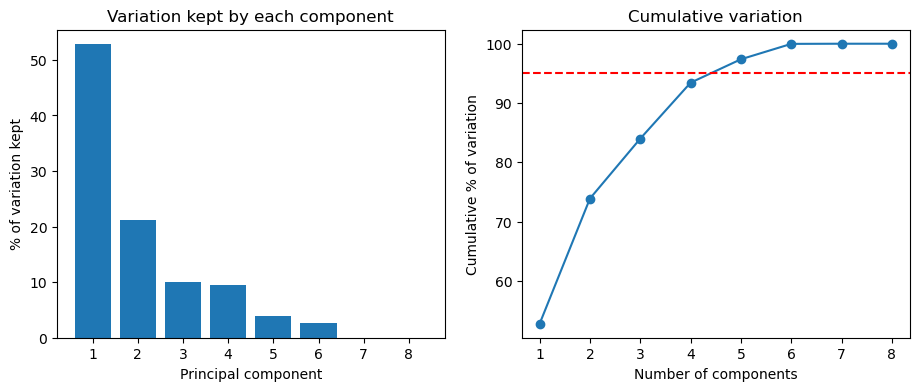

Variation kept by each component (%): [52.8 21.1 10.1  9.4  3.9  2.6  0.   0. ]
Components needed to keep 95% of the variation: 5


In [6]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(X_train_s)

ratio = pca.explained_variance_ratio_
cumulative = np.cumsum(ratio)
components_95 = int(np.argmax(cumulative >= 0.95)) + 1

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(range(1, 9), ratio * 100)
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("% of variation kept")
axes[0].set_title("Variation kept by each component")

axes[1].plot(range(1, 9), cumulative * 100, marker="o")
axes[1].axhline(95, color="red", linestyle="--")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative % of variation")
axes[1].set_title("Cumulative variation")
plt.show()

print("Variation kept by each component (%):", np.round(ratio * 100, 1))
print("Components needed to keep 95% of the variation:", components_95)

In [7]:
# What is each component made of?
loadings = pd.DataFrame(pca.components_[:3].T, index=features, columns=["PC1", "PC2", "PC3"]).round(2)
loadings

,PC1,PC2,PC3
Latitude,0.24,-0.58,0.15
Longitude,-0.16,-0.41,0.66
Well_Depth (meters),0.44,-0.00,0.12
pre_mean,0.46,0.19,0.18
post_mean,0.47,0.13,0.16
recharge,-0.16,0.60,0.21
change,0.22,-0.25,-0.64
Pre_2021,0.47,0.16,0.09


**What to say:** *The loadings show which original features each component uses. PC1 mixes the depth features (average depth, last year's depth, well depth), so it is basically 'how deep is the water'. PC2 captures differences in location and recharge.*

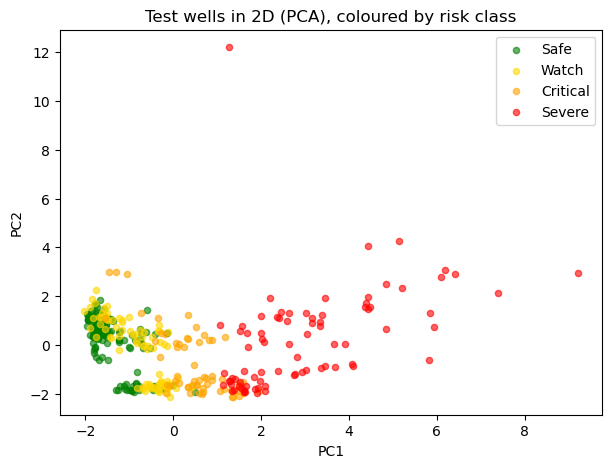

In [8]:
# Draw the test wells in 2D, coloured by true risk class
pca2 = PCA(n_components=2).fit(X_train_s)
coords = pca2.transform(X_test_s)

colors = ["green", "gold", "orange", "red"]
plt.figure(figsize=(7, 5))
for code_number, name in enumerate(labels):
    mask = (y_test == code_number).values
    plt.scatter(coords[mask, 0], coords[mask, 1], c=colors[code_number], label=name, alpha=0.6, s=20)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.title("Test wells in 2D (PCA), coloured by risk class")
plt.show()

**What to say:** *The classes spread out mainly from left to right, from Safe to Severe. PC1 is strongly related to risk (correlation about 0.85 with the risk class), while PC2 is not. So the first component alone carries most of the useful signal, which is the 'how deep is the water' idea again.*

### Using PCA before a model
**What to say:** *To check that PCA keeps the useful information, I train a linear SVM on only 3 components instead of all 8 features and compare it later with the full model.*

In [9]:
from sklearn.svm import SVC

pca3 = PCA(n_components=3).fit(X_train_s)
X_train_p = pca3.transform(X_train_s)
X_test_p = pca3.transform(X_test_s)

svm_pca = SVC(kernel="linear", probability=True, random_state=42)
svm_pca.fit(X_train_p, y_train)
evaluate("SVM (linear) on 3 PCA components", svm_pca.predict(X_test_p), svm_pca.predict_proba(X_test_p))
pd.DataFrame(results).round(3)

,Model,Accuracy,Precision,Recall,F1,At-risk recall,Log loss,AUC
0,SVM (linear) on 3 PCA components,0.805,0.8,0.792,0.796,0.936,0.458,0.955


**What to say:** *Three components keep only part of the variation (see the cumulative graph), and the accuracy is lower than the full linear SVM in the final table. So for this dataset PCA is more useful for visualising and understanding the features than for improving the model.*

## Step 4: Feedforward Neural Network (Multi-layer Perceptron)
**What to say:** *An MLP is a network of simple units arranged in layers. The input layer takes the 8 features, hidden layers combine them, and the output layer gives a probability for each of the 4 risk classes. Each unit multiplies its inputs by weights, adds them up and passes the result through an activation function (here ReLU). Training adjusts the weights by backpropagation to reduce the error. I use two hidden layers with 16 and 8 units. Neural networks need scaled inputs, which we already have.*

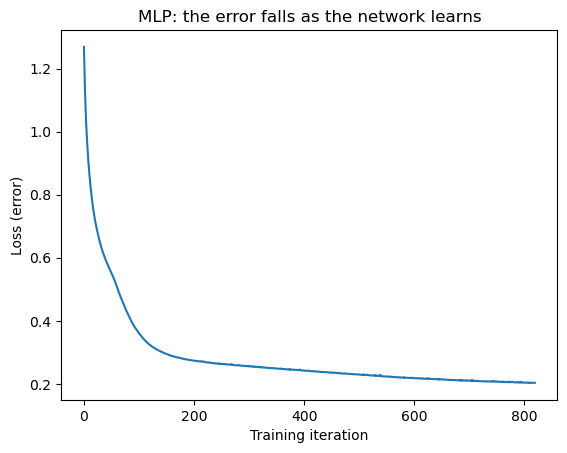

In [10]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(hidden_layer_sizes=(16, 8), activation="relu", max_iter=2000, random_state=42)
mlp.fit(X_train_s, y_train)

evaluate("MLP neural network", mlp.predict(X_test_s), mlp.predict_proba(X_test_s))

plt.plot(mlp.loss_curve_)
plt.xlabel("Training iteration")
plt.ylabel("Loss (error)")
plt.title("MLP: the error falls as the network learns")
plt.show()

## Step 5: Ensemble learning: Bagging, Random Forest and Boosting
**What to say:** *One model can be unstable, so ensembles combine many models.*

- **Bagging:** train many trees, each on a different random sample of the wells (drawn with replacement), then let them vote. Averaging reduces variance.
- **Random Forest:** bagging plus a second kind of randomness: each split looks at only a random subset of the features. This makes the trees different from each other, so the vote is stronger.
- **Boosting:** build trees one after another, where each new tree focuses on the wells the previous trees got wrong. This reduces bias.

In [11]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier

bagging = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=42)
bagging.fit(X_train, y_train)
evaluate("Bagging (100 trees)", bagging.predict(X_test), bagging.predict_proba(X_test))

forest = RandomForestClassifier(n_estimators=200, random_state=42)
forest.fit(X_train, y_train)
evaluate("Random Forest", forest.predict(X_test), forest.predict_proba(X_test))

boosting = GradientBoostingClassifier(random_state=42)
boosting.fit(X_train, y_train)
evaluate("Gradient Boosting", boosting.predict(X_test), boosting.predict_proba(X_test))

pd.DataFrame(results).round(3)

,Model,Accuracy,Precision,Recall,F1,At-risk recall,Log loss,AUC
0,SVM (linear) on 3 PCA components,0.805,0.800,0.792,0.796,0.936,0.458,0.955
1,MLP neural network,0.878,0.873,0.872,0.872,0.972,0.329,0.979
2,Bagging (100 trees),0.897,0.897,0.894,0.895,0.979,0.601,0.977
3,Random Forest,0.897,0.897,0.899,0.898,0.979,0.339,0.982
4,Gradient Boosting,0.895,0.890,0.890,0.890,0.965,0.288,0.981


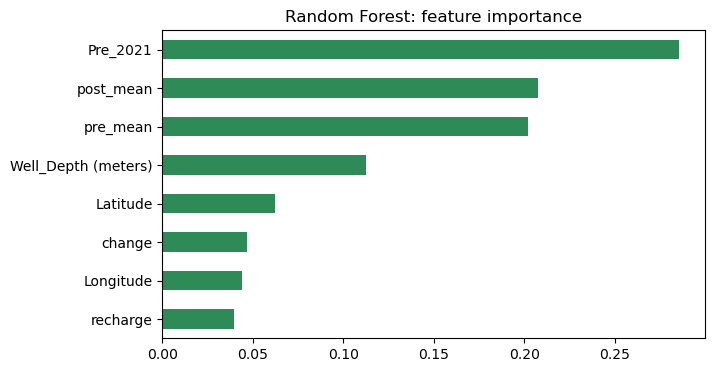

In [12]:
# Which features does the Random Forest rely on?
importance = pd.Series(forest.feature_importances_, index=features).sort_values()
importance.plot(kind="barh", figsize=(7, 4), color="seagreen")
plt.title("Random Forest: feature importance")
plt.show()

## Step 6: Bias-variance trade-off
**What to say:** *Every model makes two kinds of error.*

- **High bias (underfitting):** the model is too simple and misses real patterns. It does badly on both training and test data.
- **High variance (overfitting):** the model is too flexible and memorises the training data, including its noise. It does very well on training data but worse on new data.

*A decision tree shows this clearly, because its depth controls its flexibility. I plot training and test accuracy for depths 1 to 15. This graph is for illustration only; I do not choose the depth from the test set.*

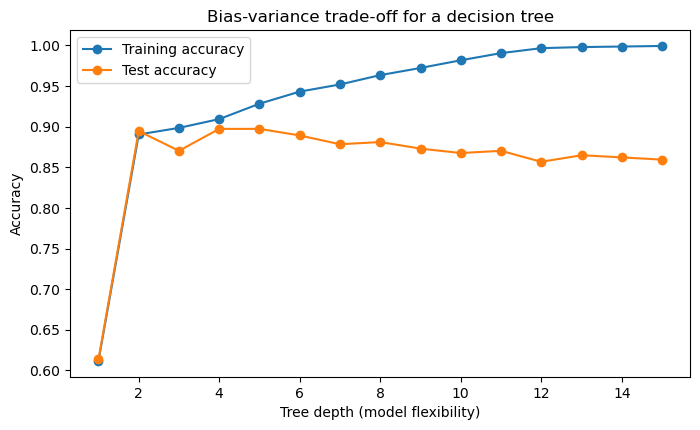

In [13]:
depths = range(1, 16)
train_acc = []
test_acc = []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_acc.append(t.score(X_train, y_train))
    test_acc.append(t.score(X_test, y_test))

plt.figure(figsize=(8, 4.5))
plt.plot(depths, train_acc, marker="o", label="Training accuracy")
plt.plot(depths, test_acc, marker="o", label="Test accuracy")
plt.xlabel("Tree depth (model flexibility)")
plt.ylabel("Accuracy")
plt.title("Bias-variance trade-off for a decision tree")
plt.legend()
plt.show()

In [14]:
# A single fully grown tree vs a Random Forest
full_tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

compare = pd.DataFrame({
    "Model": ["Single tree (no depth limit)", "Random Forest (200 trees)"],
    "Training accuracy": [full_tree.score(X_train, y_train), forest.score(X_train, y_train)],
    "Test accuracy": [full_tree.score(X_test, y_test), forest.score(X_test, y_test)]}).round(3)
compare["Gap (train - test)"] = (compare["Training accuracy"] - compare["Test accuracy"]).round(3)
compare

,Model,Training accuracy,Test accuracy,Gap (train - test)
0,Single tree (no depth limit),1.0,0.857,0.143
1,Random Forest (200 trees),1.0,0.897,0.103


**What to say:** *With very shallow trees, both accuracies are low: high bias. As the depth grows, training accuracy keeps rising towards 100% while test accuracy stops improving or drops: high variance. The gap between the two curves is the warning sign. A Random Forest averages many trees and so reduces this variance.*

## Step 7: Final comparison of all models
**What to say:** *I add the new models to the table from Practical 5, so now I can compare every model in one place. All numbers are on the 20% test wells that no model saw during training. I sort by F1 score.*

In [15]:
earlier = pd.read_csv("06_classification_results.csv")
final = pd.concat([earlier, pd.DataFrame(results).round(3)], ignore_index=True)
final = final.sort_values("F1", ascending=False).reset_index(drop=True)

print(final.to_string(index=False))

final.to_csv("08_final_model_comparison.csv", index=False)
print("Saved 08_final_model_comparison.csv")

                           Model  Accuracy  Precision  Recall    F1  At-risk recall  Log loss   AUC
            Baseline (2021 rule)     0.897      0.900   0.905 0.902           0.979       NaN   NaN
                   Decision Tree     0.897      0.897   0.906 0.900           0.972     0.474 0.970
                   Random Forest     0.897      0.897   0.899 0.898           0.979     0.339 0.982
             Bagging (100 trees)     0.897      0.897   0.894 0.895           0.979     0.601 0.977
               Gradient Boosting     0.895      0.890   0.890 0.890           0.965     0.288 0.981
              MLP neural network     0.878      0.873   0.872 0.872           0.972     0.329 0.979
                    SVM (linear)     0.862      0.860   0.854 0.855           0.972     0.302 0.981
                       SVM (RBF)     0.843      0.845   0.830 0.836           0.950     0.335 0.974
                     Naive Bayes     0.824      0.819   0.814 0.812           0.950     0.827 0.969


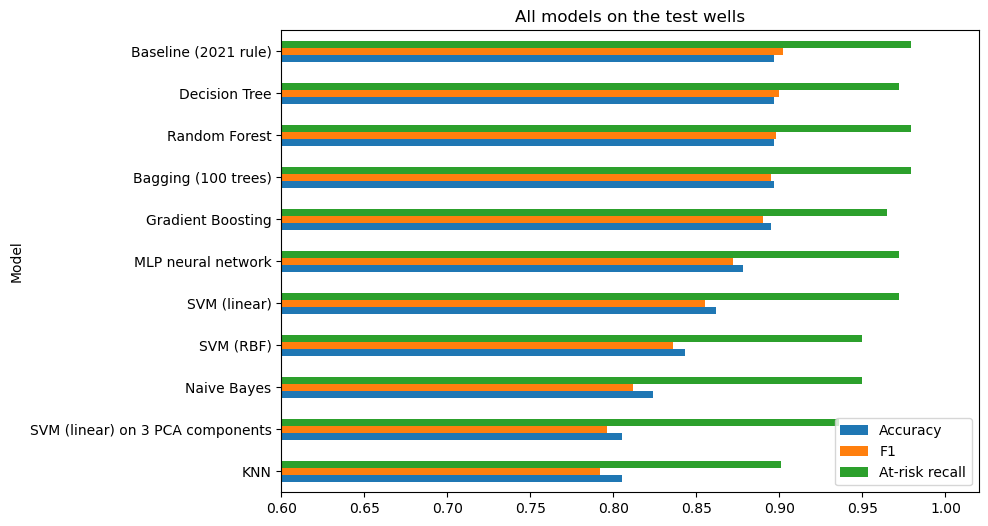

In [16]:
final.sort_values("F1").plot(x="Model", y=["Accuracy", "F1", "At-risk recall"], kind="barh", figsize=(9, 6))
plt.xlim(0.6, 1.02)
plt.title("All models on the test wells")
plt.show()

## Step 8: Confusion matrices of the new models
**What to say:** *Rows are the true class and columns the predicted class. Errors mostly sit next to the diagonal.*

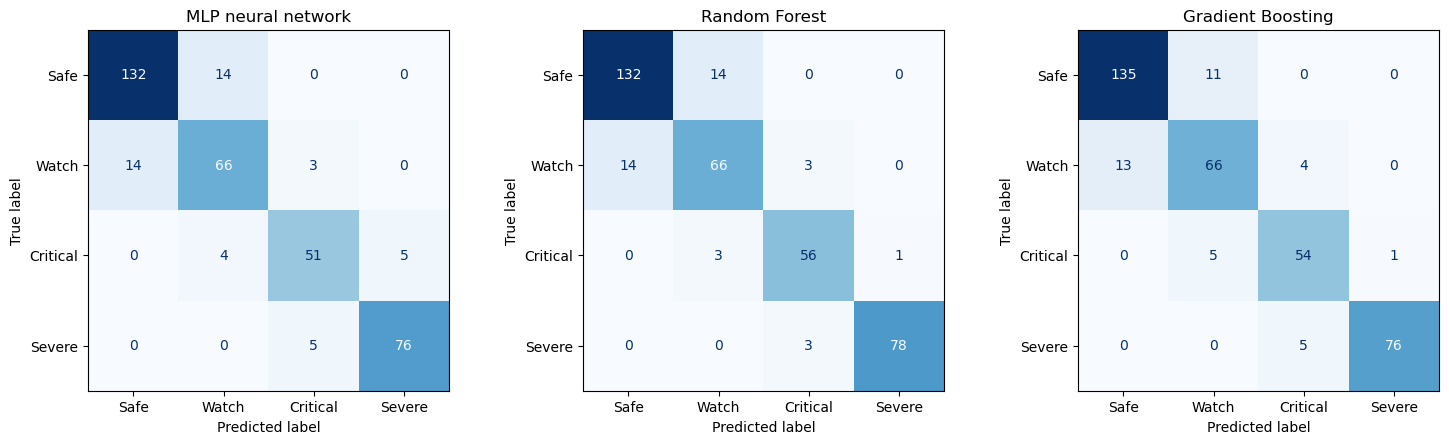

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, name in zip(axes, ["MLP neural network", "Random Forest", "Gradient Boosting"]):
    ConfusionMatrixDisplay.from_predictions(y_test, predictions[name], display_labels=labels,
                                            ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

## Step 9: Which districts need attention first?
**What to say:** *Finally I turn the analysis into something useful. I rank districts by the percentage of wells at risk (Critical or Severe) in 2022, using the district table from Practical 6. To keep the ranking reliable, I only include districts with at least 15 wells.*

In [18]:
districts = pd.read_csv("07_district_clusters.csv")

reliable = districts[districts["wells"] >= 15]
priority = reliable.sort_values("pct_at_risk", ascending=False).head(5)

priority_table = priority[["District", "State", "wells", "avg_depth_2022", "avg_change", "pct_at_risk", "cluster_name"]].reset_index(drop=True)
priority_table.index = priority_table.index + 1
print(priority_table)

priority_table.to_csv("09_priority_districts.csv")
print("Saved 09_priority_districts.csv")

       District    State  wells  avg_depth_2022  avg_change  pct_at_risk  \
1  Charki Dadri  Haryana     19           68.79        4.75       100.00   
2   Kurukshetra  Haryana     53           40.12        5.56        98.11   
3   Gandhinagar  Gujarat     54           81.84        4.81        96.30   
4  Mahendragarh  Haryana     53           49.98        4.77        88.68   
5   Banaskantha  Gujarat     91           61.16        4.33        83.52   

  cluster_name  
1  High stress  
2  High stress  
3  High stress  
4  High stress  
5  High stress  
Saved 09_priority_districts.csv


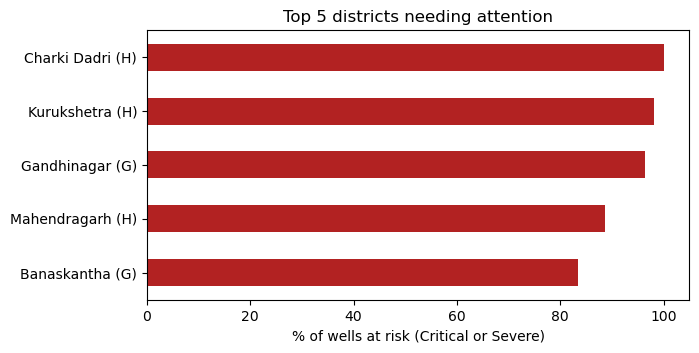

In [19]:
priority.sort_values("pct_at_risk").plot(x="label", y="pct_at_risk", kind="barh", legend=False, color="firebrick", figsize=(7, 3.5))
plt.xlabel("% of wells at risk (Critical or Severe)")
plt.ylabel("")
plt.title("Top 5 districts needing attention")
plt.show()

## Conclusion
**What to say:** *PCA showed that our eight features overlap heavily: the first component alone is basically 'how deep is the water'. But it took five components to keep 95% of the variation, and using only three lowered the accuracy, so PCA helped me understand and visualise the data more than it improved the models. The neural network and the ensemble methods were compared against simpler models using the same test wells. Because groundwater depth changes slowly, no model clearly beats the simple rule of using last year's depth, so I recommend the model that is easiest to explain. The district ranking is the most useful result: it shows which districts need attention first.*